# Pregunta 1 · Detección de anomalías de rodilla en RM (RSNA, Kaggle)
**Redes Neuronales y Aprendizaje Profundo · UNI FIIS 2026-II · Examen Parcial · Sección C**

Clasificación multietiqueta de 12 hallazgos de rodilla en resonancia magnética, con **supervisión débil**: las etiquetas de
entrenamiento se extraen automáticamente de reportes radiológicos en varios idiomas y los ~58 estudios con etiqueta dorada
sirven como validación limpia. Métrica oficial: **macro-AUC**.

| Entregable del examen | Dónde se resuelve en este cuaderno |
|---|---|
| 1. Etiquetas débiles validadas vs. dorados | §5 (v1 → v2 → ensemble, acuerdo, κ, ruido) |
| 2. Arquitecturas: CNN propia + transferencia ImageNet | §7 (experimentos `scratch_*` y `timm_*`) |
| 3. Macro-AUC, AUC por hallazgo, P/R/F1 | §8 |
| 4. Ablaciones (plano, BCE vs focal, ruido, profundidad, pooling) | §7–§8 (comparación e IC pareados) |
| 5. Grad-CAM en ≥ 3 hallazgos | §8 |
| 6. Desbalance y subconjunto estratificado (300–600) | §6 |
| 7. Sesgo geográfico / lingüístico | §5 (sensibilidad por idioma) |

> Trabajo individual: los demás integrantes del grupo se retiraron; esto está informado al profesor.

**Antes de correr** (panel derecho → *Session options*):
1. **Accelerator: GPU T4 ×2** (o P100). **Internet: On** (hace falta para `pip` y para los pesos ImageNet).
2. *Input*: la competencia **RSNA Knee Abnormality Detection** (sección COMPETITIONS, con archivos `.dcm`) y tu dataset **`knee-mri-code`**.
3. Corre **primero con `MODO = "prueba"`** (≈ 20–30 min). Si todo sale bien, cambia a `"completo"`.



## 1 · Panel de control

In [1]:
MODO  = "completo"   # "prueba" = datos reales reducidos (rápido)  |  "completo" = corrida final
GRUPO = "A,B"        # solo modo completo: "A" = 6 experimentos esenciales | "B" = extras | "A,B" = todos
PARALELO = True    # con 2 GPU (T4 x2) corre dos experimentos a la vez
RESUMIR_DESDE = None   # tras una versión anterior: ruta de su salida, p. ej. "/kaggle/input/pregunta-1-v1/work"
EXTRA = ""         # sobrescrituras avanzadas, p. ej. "train.batch_size=1 train.img_size=192" si falta memoria de GPU

## 2 · Preparación (localiza el código y los datos solos, instala dependencias)

In [2]:
import glob, json, os, shutil, subprocess, sys, time, zipfile
import yaml

KAGGLE = os.environ.get("KAGGLE_ROOT", "/kaggle")
IN_DIR, WORK_ROOT = f"{KAGGLE}/input", f"{KAGGLE}/working"
assert MODO in ("prueba", "completo"), "MODO debe ser 'prueba' o 'completo'"


def sh(cmd, cwd=None, env=None):
    # Ejecuta un comando mostrando su salida en vivo; falla si el comando falla.
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                         cwd=cwd, env={**os.environ, **(env or {})})
    for line in p.stdout:
        if "Warning" in line or "warn(" in line:
            continue
        print(line, end="")
    p.wait()
    if p.returncode != 0:
        raise RuntimeError(f"El comando falló (código {p.returncode}): {cmd}")


def buscar(archivos, maxdepth=6):
    # Carpetas bajo /kaggle/input que contienen todos los `archivos` (sin entrar a train_series/test_series).
    for dp, dirs, files in os.walk(IN_DIR):
        depth = dp[len(IN_DIR):].count(os.sep)
        dirs[:] = [] if depth >= maxdepth else [d for d in dirs if d not in ("train_series", "test_series")]
        if all(a in files for a in archivos):
            yield dp


def es_dicom(d):
    try:
        a = next(os.scandir(f"{d}/train_series")); b = next(os.scandir(a.path)); f = next(os.scandir(b.path))
        return f.name.lower().endswith(".dcm")
    except Exception:
        return False


# --- código
cands = [os.path.dirname(d) for d in buscar(["config.py"]) if os.path.basename(d) == "src"
         and os.path.exists(os.path.join(os.path.dirname(d), "run_all.sh"))]
assert cands, f"No encuentro el código. Agrega el dataset 'knee-mri-code' como Input. Contenido de {IN_DIR}: {os.listdir(IN_DIR)}"
CODE_SRC = cands[0]
CODE = f"{WORK_ROOT}/knee-mri"
if os.path.exists(CODE):
    shutil.rmtree(CODE)
shutil.copytree(CODE_SRC, CODE, ignore=shutil.ignore_patterns("work*", "synthetic_data", "__pycache__"))

# --- datos (deben ser DICOM oficiales, no una copia en JPEG)
datos = list(buscar(["train.csv", "train_series.csv", "sample_submission.csv"]))
print("Carpetas con train.csv encontradas:", datos)
oficiales = [d for d in datos if es_dicom(d)]
assert oficiales, ("No encuentro la competencia con archivos .dcm. ¿Agregaste la competencia oficial (sección COMPETITIONS) "
                   "y no un dataset en JPEG? Revisa el panel Input.")
DATA = oficiales[0]

# --- dependencias
def pip(pkgs):
    r = subprocess.run(f"pip install -q {' '.join(pkgs)}", shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        for p in pkgs:  # uno por uno, para saber cuál falla
            r = subprocess.run(f"pip install -q {p}", shell=True, capture_output=True, text=True)
            print(("  ok  " if r.returncode == 0 else "  FALLA ") + p)

if not os.environ.get("SKIP_PIP"):
    pip(["pylibjpeg", "pylibjpeg-libjpeg", "pylibjpeg-openjpeg", "pydicom", "langdetect", "tabulate", "timm"]
        + (["sentence-transformers"] if MODO == "completo" else []))

# --- rutas y configuración del modo elegido
WORK, NPY = f"{WORK_ROOT}/work", f"{KAGGLE}/temp/npy"
os.makedirs(WORK, exist_ok=True); os.makedirs(NPY, exist_ok=True)
CFG = "configs/solo_prueba.yaml" if MODO == "prueba" else "configs/default.yaml"
OV = f"--set paths.data_root={DATA} paths.work_dir={WORK} paths.npy_dir={NPY} {EXTRA}".strip()
if RESUMIR_DESDE:
    sh(f"cp -rn '{RESUMIR_DESDE}/.' '{WORK}/'")
print(f"\nMODO={MODO} | código={CODE} | datos={DATA}\nconfig={CFG}")

Carpetas con train.csv encontradas: ['/kaggle/input/competitions/rsna-knee-abnormality-detection']

MODO=completo | código=/kaggle/working/knee-mri | datos=/kaggle/input/competitions/rsna-knee-abnormality-detection
config=configs/default.yaml


## 3 · Entorno (GPU, CPU, memoria)

In [3]:
import torch
ngpu = torch.cuda.device_count()
print("GPU:", [torch.cuda.get_device_name(i) for i in range(ngpu)] or "NINGUNA")
print("CPU:", os.cpu_count(), "| torch", torch.__version__)
sh("free -g | head -2; df -h /kaggle/working /kaggle/temp 2>/dev/null | tail -2")
if ngpu == 0:
    print("\n⚠ Sin GPU: la prueba funcionará (lenta) pero el modo completo NO. Settings → Accelerator → GPU T4 x2.")
    assert MODO == "prueba", "El modo completo necesita GPU. Activa Settings → Accelerator → GPU T4 x2 y reinicia la sesión."

GPU: ['Tesla T4', 'Tesla T4']
CPU: 4 | torch 2.11.0+cu128
               total        used        free      shared  buff/cache   available
Mem:              31           1          24           0           5          29
/dev/loop2       20G  408K   20G   1% /kaggle/working
overlay         8.0T  7.0T  1.1T  87% /


## 4 · Diagnóstico con datos reales (≈ 2–4 min)
Decodifica series de muestra, informa qué códecs DICOM hay, cuántos estudios dorados existen y **estima el tiempo del preprocesamiento**.

In [4]:
sh(f"python -m src.diagnose --config {CFG} {OV}", cwd=CODE)

train.csv: 4407 estudios | dorados: 58 | con reporte: 4407
train_series.csv: 24371 series | estudios únicos: 4407
Anatomical_Plane  Fluid_Sensitive  Fat_Suppression
Axial             0                0                  1179
                  1                1                  4719
Coronal           0                0                  3985
                  1                1                  4624
Sagittal          0                0                  5197
                  1                1                  4667

Series probadas: 45 | decodificadas: 45 | mediana de cortes: 30
Transfer syntaxes (último tramo del UID): {'1': 45}

Tiempo mediano por serie: 0.42s → preprocesar ≈1674 series con 4 procesos ≈ 3 min


## 5 · Etiquetas débiles desde los reportes + validación contra los estudios dorados (entregables 1 y 7)
Al final se imprimen **ejemplos donde el extractor discrepa de la etiqueta dorada**: 

In [5]:
sh(f"python -m src.labels.extract --config {CFG} {OV}", cwd=CODE)
sh(f"python -m src.labels.validate --config {CFG} {OV}", cwd=CODE)
print("\n" + open(f"{WORK}/labels/validation_report.md").read())

[labels] estudios: 4407 | dorados: 58

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2670.73it/s]

Batches: 100%|██████████| 1347/1347 [02:05<00:00, 10.73it/s]
[labels] modo=ensemble → /kaggle/working/work/labels/weak_labels.csv
[labels] prevalencia débil (no dorados):
ACL                 0.169
MCL                 0.099
Medial Meniscus     0.416
Lateral Meniscus    0.209
Medial OA           0.160
Lateral OA          0.116
PF OA               0.244
Effusion            0.462
Synovitis           0.108
Baker's             0.231
Contusion           0.201
Fracture            0.071
[labels] extractor de reglas v2
[labels] idiomas y fracción de reportes comprendidos:
         n  comprendido
lang                   
en    1736         1.00
es     682         0.75
tr     546         0.89
hr     406         0.96
el     321         0.93
de     262         0.98
bg     220         0.98
nl     153         0.90
fr      81         1.00
        agreement  sensitivity  specificity     f1  kappa 

### 5.1 · Iteraciones del extractor: ¿mejoró de v1 a v2?
La **v1** se escribió sin ver los reportes reales. Al medirla contra los dorados falló sobre todo en búlgaro, griego y croata
(sensibilidad ≈ 0) y asumía artrosis «medial» sin evidencia. La **v2** añade léxico por idioma, encabezados de sección,
«grado 1 = incierto» en ligamentos y descarta defectos condrales focales. Para no sobreajustar, los dorados se parten en mitades
*dev* (se puede mirar) y *test* (solo se mide).

                   version parte  n  acuerdo  sensibilidad  kappa_medio  tasa_ruido
     v1 · reglas iniciales todos 58    0.759         0.617        0.436       0.241
     v1 · reglas iniciales   dev 29    0.764         0.591        0.413       0.236
     v1 · reglas iniciales  test 29    0.753         0.640        0.450       0.247
     v2 · reglas ampliadas todos 58    0.782         0.704        0.486       0.218
     v2 · reglas ampliadas   dev 29    0.787         0.704        0.465       0.213
     v2 · reglas ampliadas  test 29    0.776         0.704        0.495       0.224
ensemble · v2 + embeddings todos 58    0.782         0.704        0.486       0.218
ensemble · v2 + embeddings   dev 29    0.787         0.704        0.465       0.213
ensemble · v2 + embeddings  test 29    0.776         0.704        0.495       0.224
version  ensemble · v2 + embeddings  v1 · reglas iniciales  v2 · reglas ampliadas
idioma                                                                        

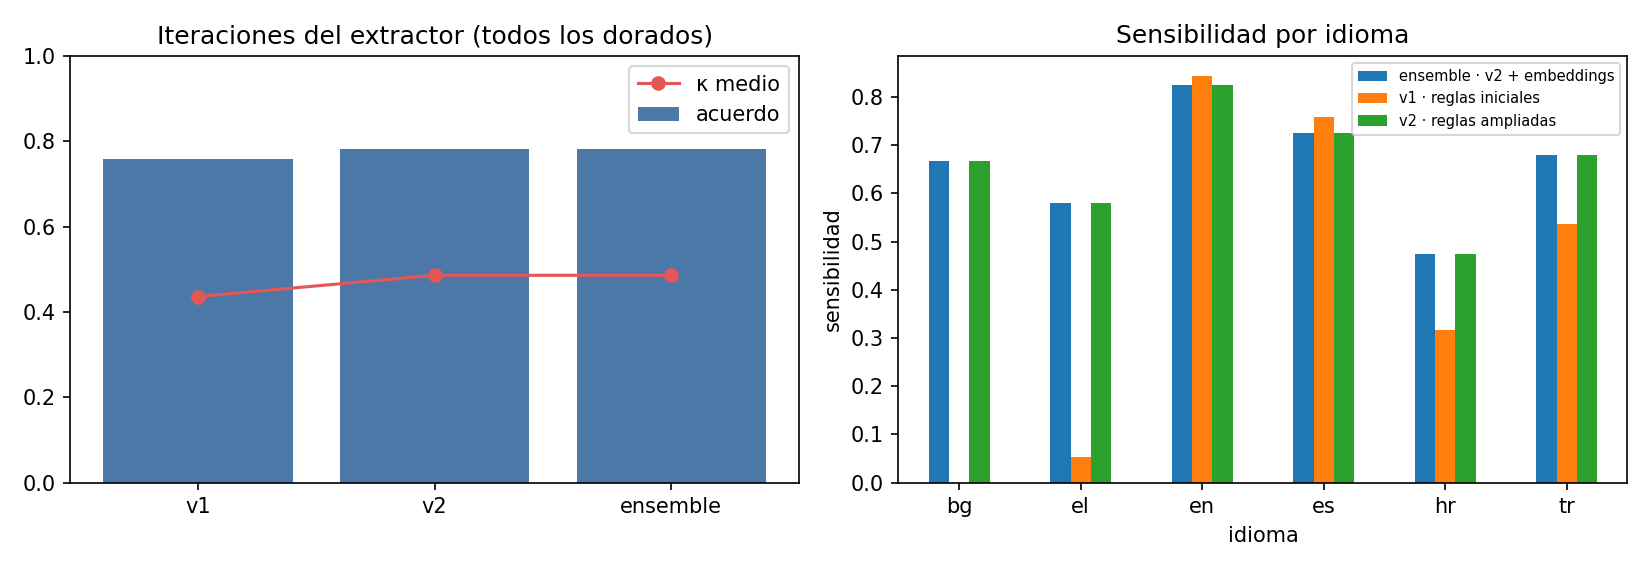

In [6]:
sh(f"python -m src.labels.compare_versions --config {CFG} {OV}", cwd=CODE)
from IPython.display import Image, display
display(Image(f"{WORK}/reports/extractor_iteraciones.png"))

### 5.2 · Sesgo lingüístico (entregable 7)
La tabla de sensibilidad por idioma muestra que el extractor —y por lo tanto las etiquetas débiles— **no rinde igual en todos los
idiomas**: los reportes en idiomas peor cubiertos quedan con más falsos negativos, y el modelo hereda ese ruido. Es un sesgo de
representación (qué instituciones/países reportan en qué idioma) que se discute en el informe junto con la distribución geográfica.

In [7]:
import pandas as pd
sys.path.insert(0, CODE)
from src.config import LABELS
w = pd.read_csv(f"{WORK}/labels/weak_labels.csv")
rep = pd.read_csv(f"{DATA}/train.csv").set_index("StudyInstanceUID")["Report"].fillna("")
casos = []
for _, r in w[w.is_gold == 1].iterrows():
    for lab in LABELS:
        if int(r[lab]) != int(r[f"{lab}__gold"]):
            casos.append((r.StudyInstanceUID, r.lang, lab, int(r[f"{lab}__gold"]), int(r[lab]), r[f"{lab}__state"]))
print(f"Discrepancias extractor vs dorado: {len(casos)} de {int((w.is_gold == 1).sum()) * len(LABELS)} etiquetas\n")
vistos = set()
for uid, lang, lab, gold, weak, state in casos:
    if uid in vistos or len(vistos) >= 8:
        continue
    vistos.add(uid)
    print(f"── {lab} | dorado={gold} extractor={weak} (estado={state}) | idioma={lang}\n{rep[uid][:450]}\n")

Discrepancias extractor vs dorado: 152 de 696 etiquetas

── PF OA | dorado=1 extractor=0 (estado=NONE) | idioma=es
Antecedentes Clínicos:
Esguince rodilla. [DATE].
Hallazgos:
No hay alteraciones de señal significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Amputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal
conservada, sin signos de rotura.
Cartílagos de los compartimentos femorotibiales sin alteraciones.
Fina úlcera condral focal de espesor total del aspecto inferior de la vertie

── PF OA | dorado=1 extractor=0 (estado=NONE) | idioma=en
 The study reveals normal knee joint alignment.   No fracture is seen.  
   ACL is intact.   PCL is preserved.  
  The MCL is intact.    Medial meniscus is not torn.  
  The FCL, popliteus and biceps femoris tendons are preserved.       
   Horizontal tear at anterior horn of the lateral meniscus is noted.  
   Focal osteochondral defect at lateral patellar facet, about 8x

## 6 · Selección estratificada de estudios y preprocesamiento DICOM → volúmenes 2.5D (entregable 6)

In [8]:
sh(f"python -m src.data.select_studies --config {CFG} {OV}", cwd=CODE)
t0 = time.time()
sh(f"python -m src.data.preprocess --config {CFG} {OV}", cwd=CODE)
print(f"\nPreprocesamiento: {(time.time() - t0) / 60:.1f} min")
sh(f"du -sh {NPY}")

[select] candidatos con planos ['Sagittal']: 4059 | dorados: 58
split
train    425
val       75
gold      58
[select] prevalencia:
conjunto          dorado  train  val_interna
label                                       
ACL                0.414  0.238        0.213
MCL                0.155  0.155        0.133
Medial Meniscus    0.448  0.438        0.387
Lateral Meniscus   0.397  0.228        0.240
Medial OA          0.259  0.202        0.200
Lateral OA         0.190  0.151        0.160
PF OA              0.362  0.271        0.253
Effusion           0.603  0.511        0.507
Synovitis          0.466  0.181        0.120
Baker's            0.207  0.292        0.293
Contusion          0.328  0.242        0.253
Fracture           0.310  0.108        0.080
[preprocess] 1674 series a procesar con 4 procesos
  200/1674
  400/1674
  600/1674
  800/1674
  1000/1674
  1200/1674
  1400/1674
  1600/1674
plane     status
Axial     ok        558
Coronal   ok        558
Sagittal  ok        558

Prepro

### 6.1 · Prevalencia y desbalance
El subconjunto se estratifica para garantizar positivos de hallazgos raros. Además, **la prevalencia en los dorados difiere de la débil**
(desajuste de distribución): es una limitación a reportar y una razón para usar *pos_weight*, focal loss y sobremuestreo.

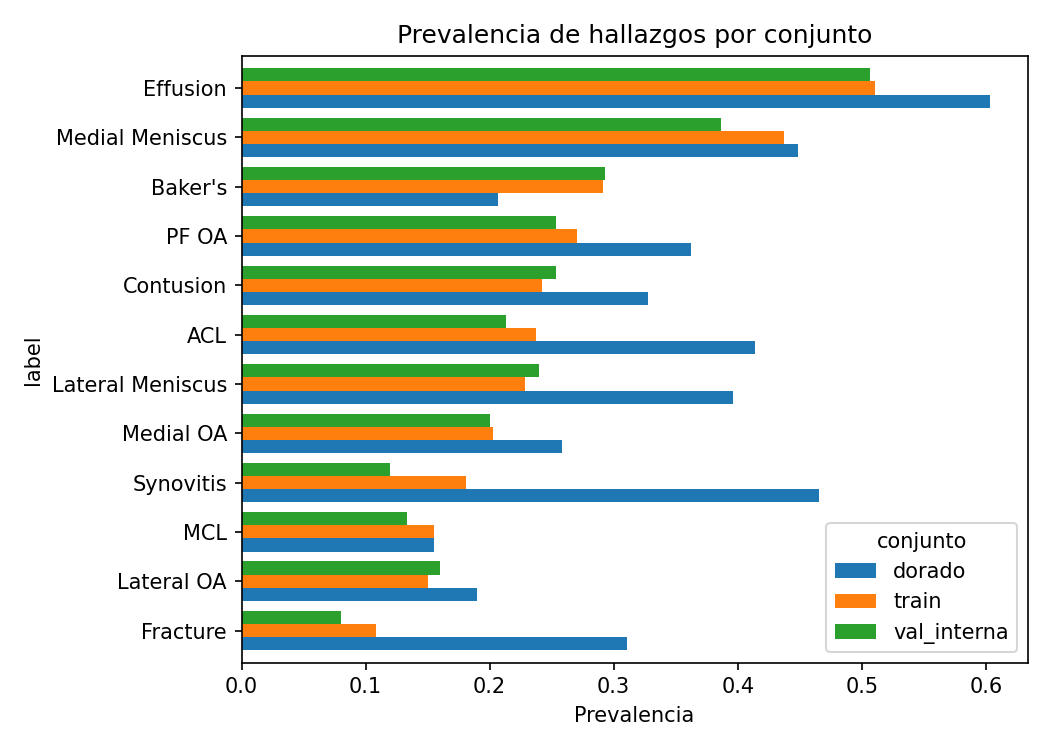

In [9]:
display(Image(f"{WORK}/reports/prevalence.png"))

## 7 · Entrenamiento y ablaciones (entregables 2, 3 y 4)
- **prueba**: 3 experimentos cortos (ResNet-18 preentrenada, BCE, CNN desde cero).
- **completo**: los del `GRUPO` elegido. Con 2 GPU se corren dos a la vez.

In [10]:
cfg = yaml.safe_load(open(f"{CODE}/{CFG}"))
grupos = set(GRUPO.replace(" ", "").split(","))
names = [a["name"] for a in cfg["ablations"] if MODO == "prueba" or a.get("group", "A") in grupos]
pend = [n for n in names if not os.path.exists(f"{WORK}/runs/{n}/metrics.json")]
print("Experimentos del modo:", names, "\nPendientes:", pend)

ngpu = torch.cuda.device_count()
par = PARALELO and ngpu >= 2
chunks = [pend[0::2], pend[1::2]] if par else [pend]
os.makedirs(f"{WORK}/logs", exist_ok=True)
procs = []
for i, ch in enumerate(chunks):
    if not ch:
        continue
    log = open(f"{WORK}/logs/proceso{i}.log", "w")
    extra = "train.num_workers=2" if par else ""
    env = {**os.environ, "CUDA_VISIBLE_DEVICES": str(i)} if par else dict(os.environ)
    cmd = f"python -m src.ablation --config {CFG} {OV} {extra} --only {','.join(ch)}"
    procs.append((i, ch, subprocess.Popen(cmd, shell=True, cwd=CODE, stdout=log, stderr=subprocess.STDOUT, env=env)))
    print(f"proceso {i} ({'GPU ' + str(i) if par else 'GPU/CPU por defecto'}): {ch}")

ultimo = {}
t0 = time.time()
while any(p.poll() is None for _, _, p in procs):
    time.sleep(60)
    for i, ch, p in procs:
        lines = [l for l in open(f"{WORK}/logs/proceso{i}.log").read().splitlines() if l.strip() and "Warning" not in l]
        if lines and lines[-1] != ultimo.get(i):
            ultimo[i] = lines[-1]
            print(f"[{(time.time() - t0) / 60:5.0f} min] proceso {i}: {lines[-1][:150]}")
for i, ch, p in procs:
    txt = open(f"{WORK}/logs/proceso{i}.log").read()
    print(f"\nproceso {i}: código de salida {p.returncode} | errores en el log: {txt.count('Traceback')}")
    if "Traceback" in txt:
        print(txt[txt.index("Traceback"):][:2500])
faltan = [n for n in names if not os.path.exists(f"{WORK}/runs/{n}/metrics.json")]
assert not faltan, f"Estos experimentos NO terminaron: {faltan}. Revisa los errores de arriba (lo más común: Internet apagado)."
print(f"\nTiempo total de entrenamiento: {(time.time() - t0) / 60:.0f} min")

Experimentos del modo: ['base', 'loss_bce', 'noisy_highconf', 'plane_sag_only', 'resnet18', 'scratch_C1_k3_max_avg', 'noisy_all', 'plane_sag_cor', 'mil_max', 'mil_mean', 'gpool_avg', 'effnet_b0', 'loss_bce_noposw', 'scratch_C2_k5first', 'scratch_C3_avgpool', 'scratch_C4_stride_gmax', 'scratch_C5_5blocks_avgmax'] 
Pendientes: ['base', 'loss_bce', 'noisy_highconf', 'plane_sag_only', 'resnet18', 'scratch_C1_k3_max_avg', 'noisy_all', 'plane_sag_cor', 'mil_max', 'mil_mean', 'gpool_avg', 'effnet_b0', 'loss_bce_noposw', 'scratch_C2_k5first', 'scratch_C3_avgpool', 'scratch_C4_stride_gmax', 'scratch_C5_5blocks_avgmax']
proceso 0 (GPU 0): ['base', 'noisy_highconf', 'resnet18', 'noisy_all', 'mil_max', 'gpool_avg', 'loss_bce_noposw', 'scratch_C3_avgpool', 'scratch_C5_5blocks_avgmax']
proceso 1 (GPU 1): ['loss_bce', 'plane_sag_only', 'scratch_C1_k3_max_avg', 'plane_sag_cor', 'mil_mean', 'effnet_b0', 'scratch_C2_k5first', 'scratch_C4_stride_gmax']
[    1 min] proceso 0: [train:base] cuda | train=425

## 8 · Resultados: tabla de ablaciones, Grad-CAM (entregable 5) y curvas ROC

              experimento                                                                 cambios  macro_auc_dorado  ic95_inf  ic95_sup  macro_auc_val_interna  macro_f1_dorado
          loss_bce_noposw              train.loss=bce, train.pos_weight=False, train.sampler=none            0.6462    0.5860    0.7044                 0.7395           0.4062
                 mil_mean                                                     model.mil_pool=mean            0.6440    0.5849    0.6997                 0.7392           0.4229
                noisy_all                                                  train.noisy_labels=all            0.6385    0.5831    0.6929                 0.6995           0.4714
                gpool_avg                                                   model.global_pool=avg            0.6355    0.5825    0.6866                 0.7234           0.4445
                  mil_max                                                      model.mil_pool=max            0.6293    0

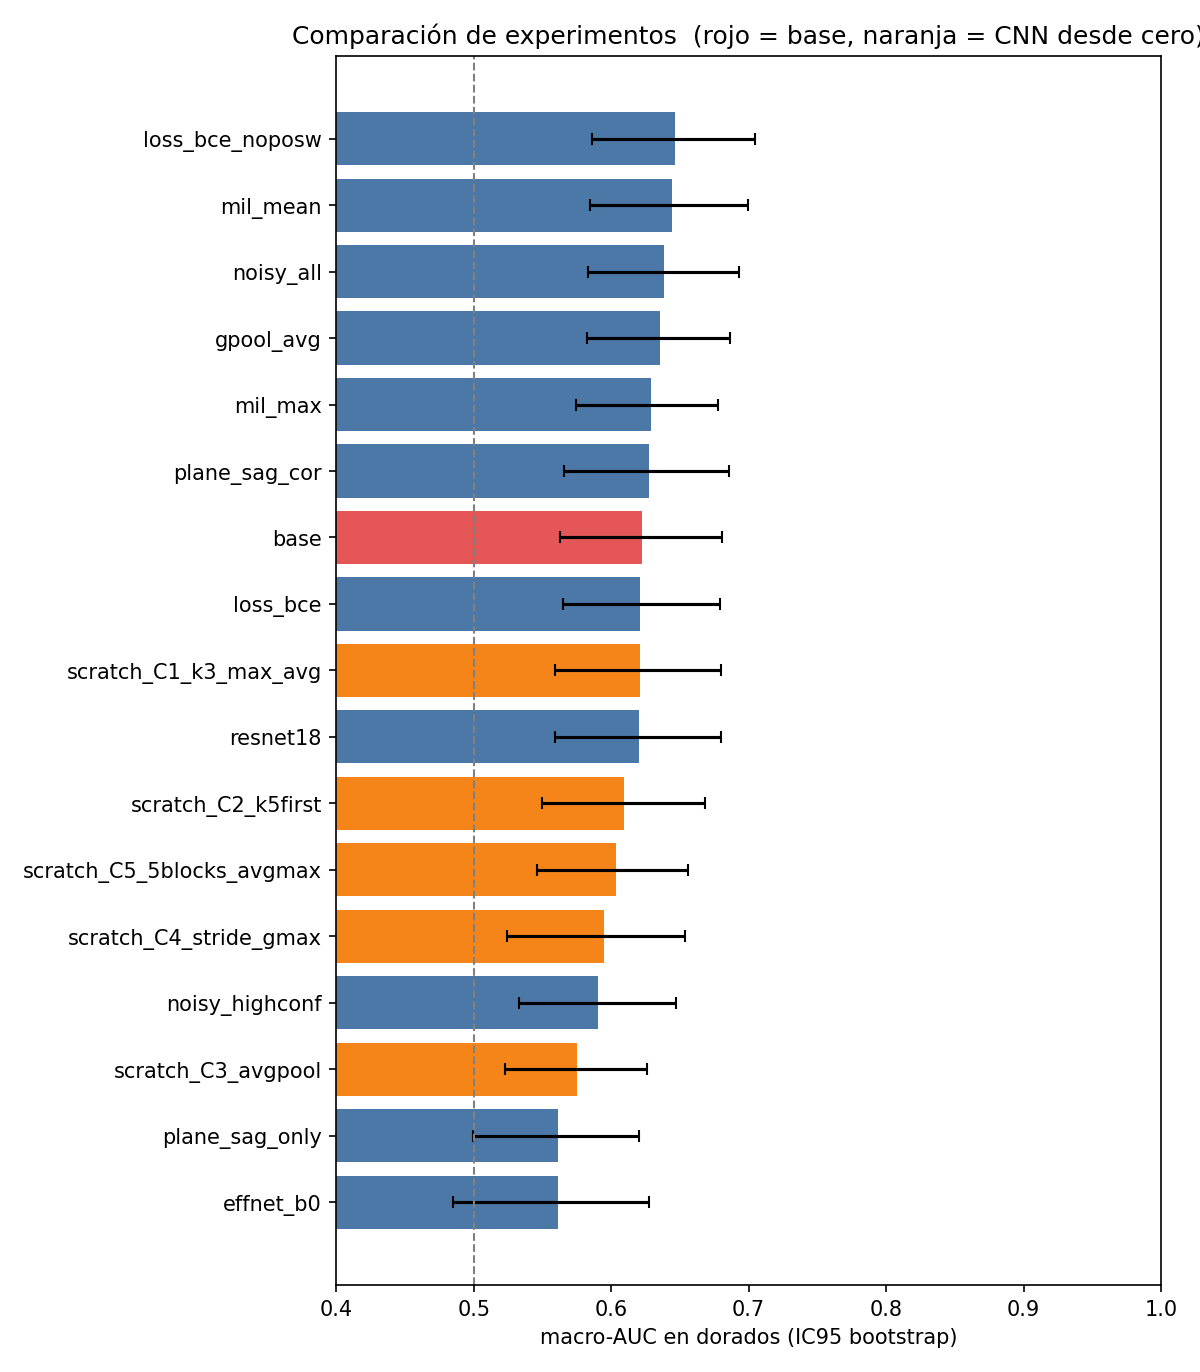

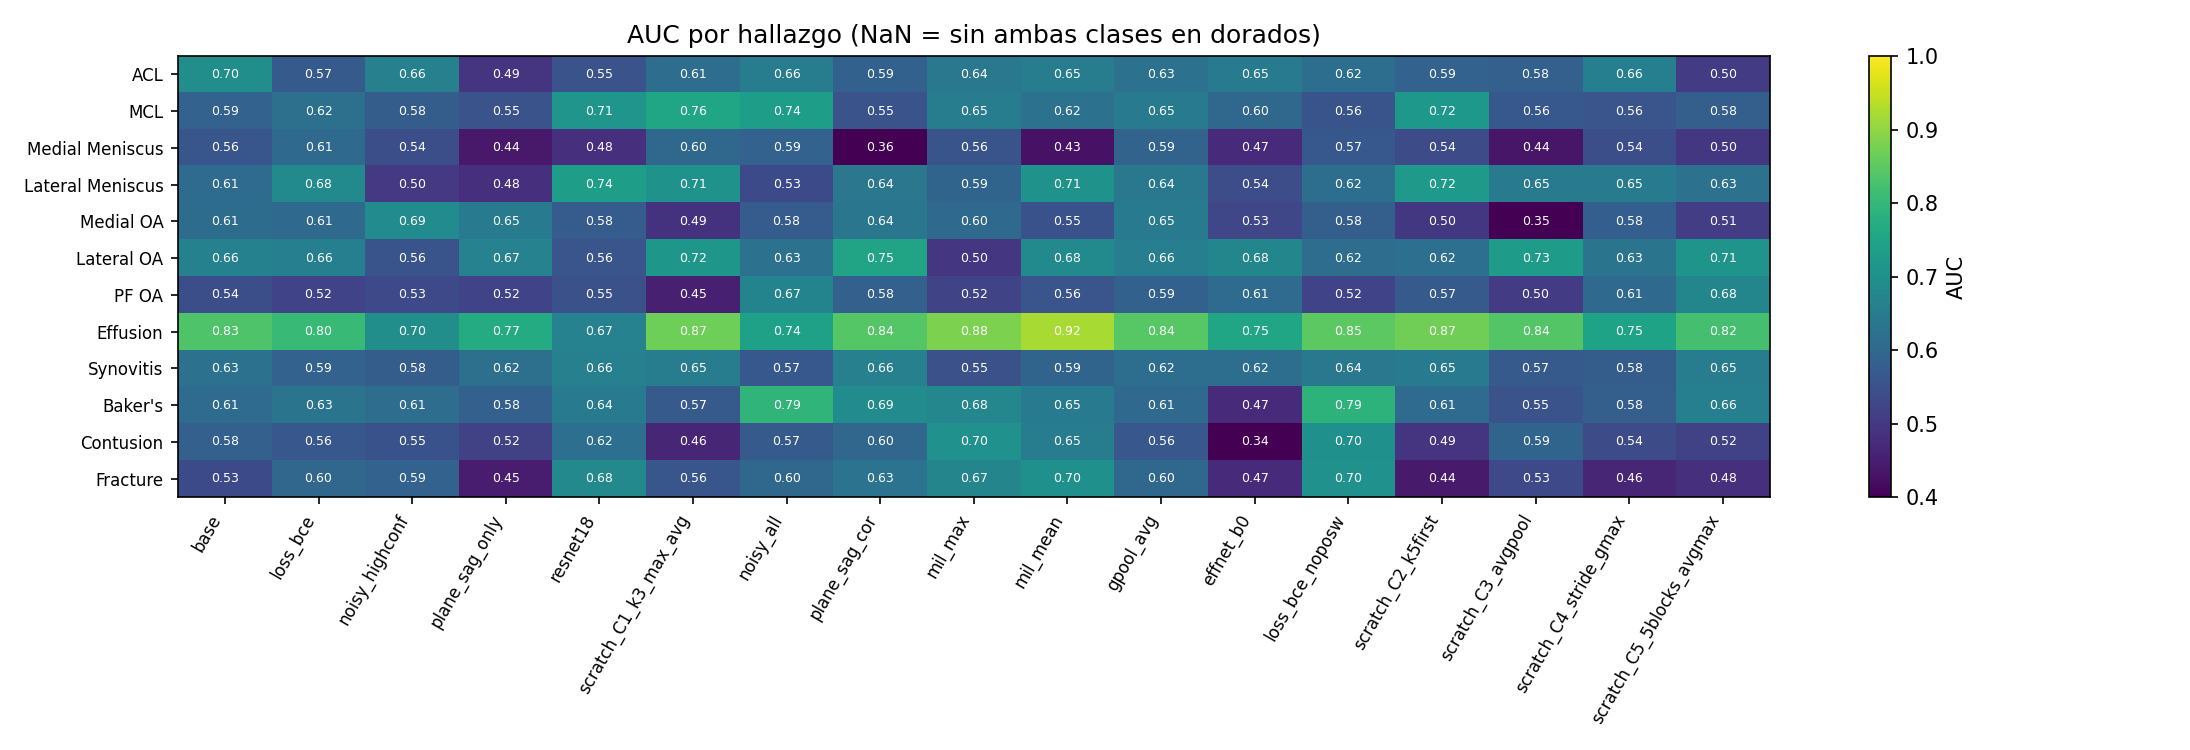

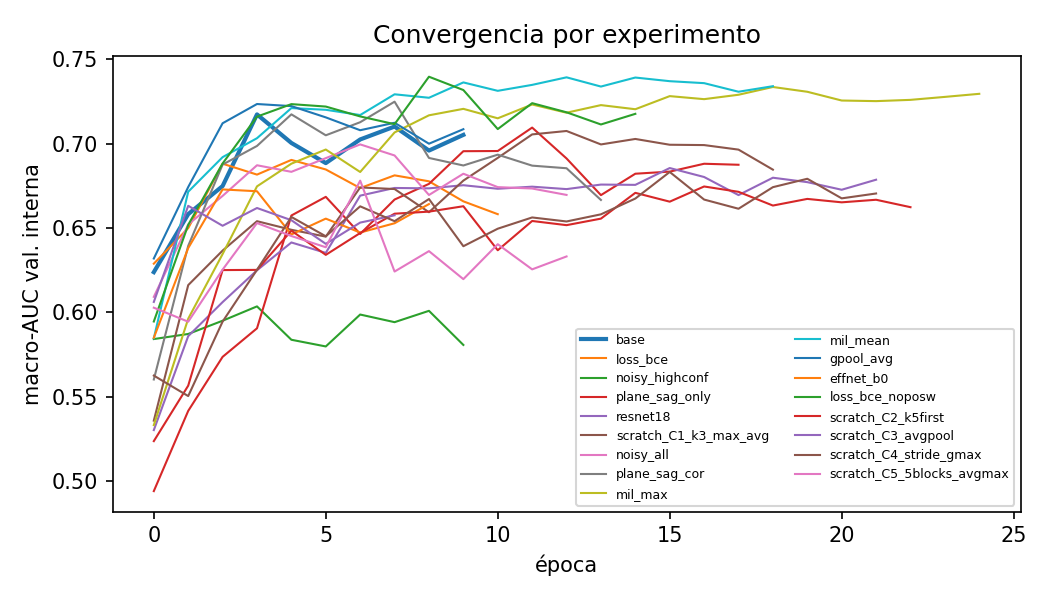

[gradcam] 15 figuras en /kaggle/working/work/runs/base/gradcam (fuente: dorado)
ACL_13570435.png


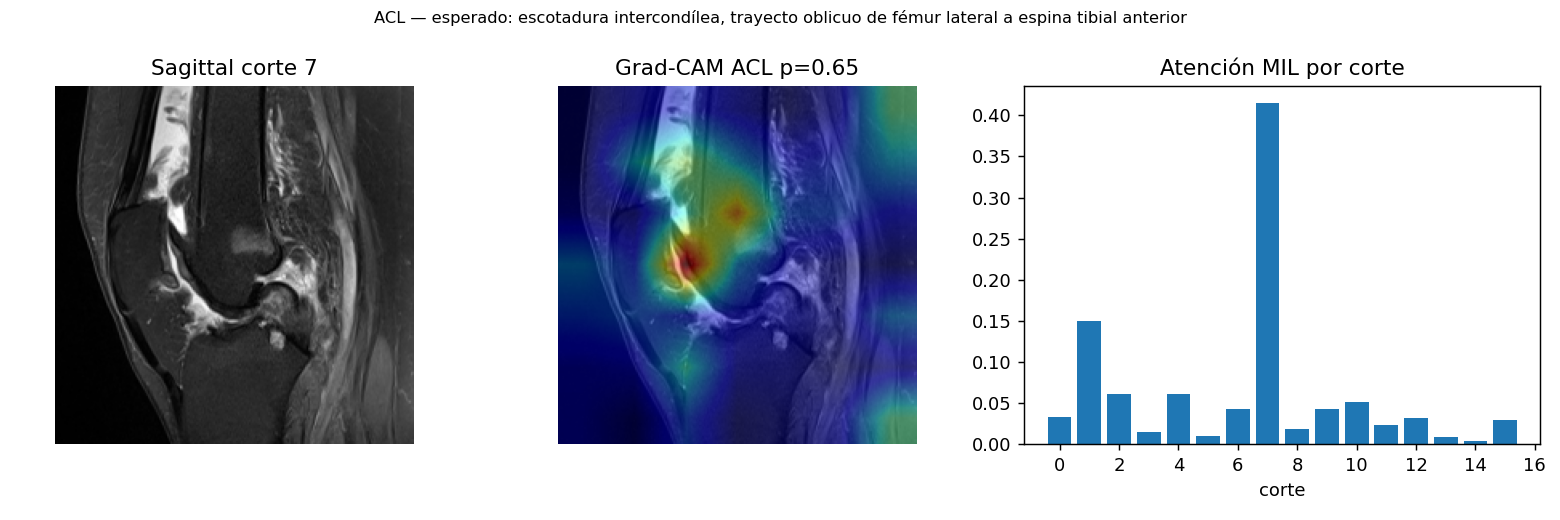

ACL_39890254.png


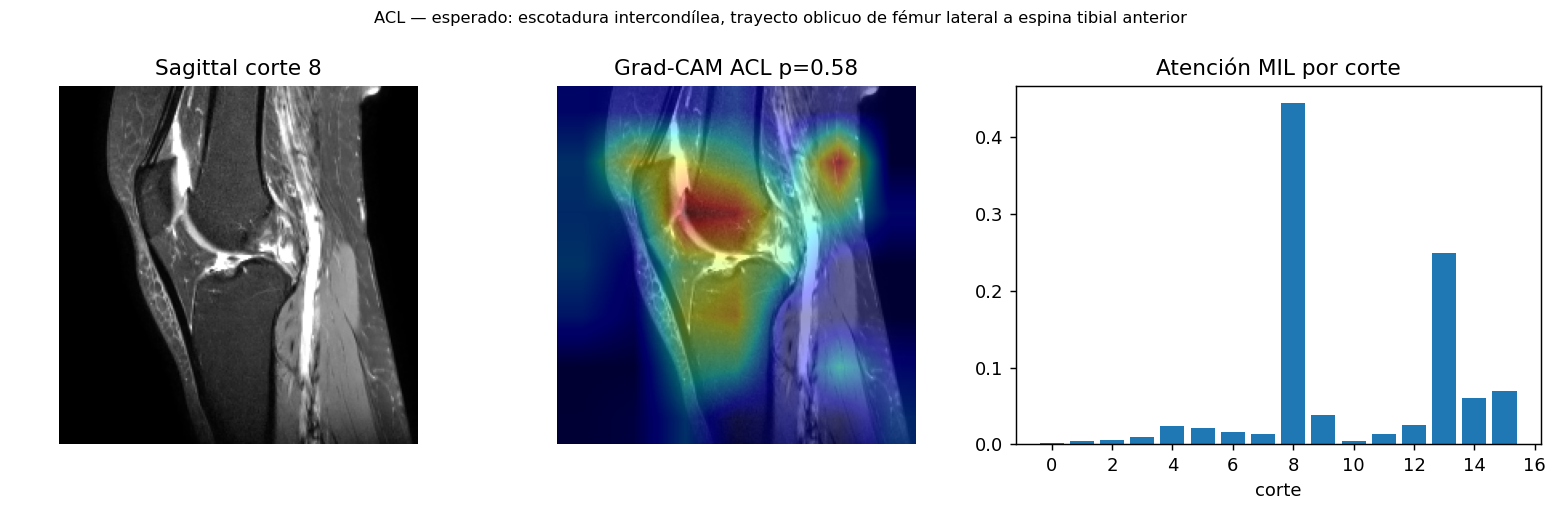

ACL_67212742.png


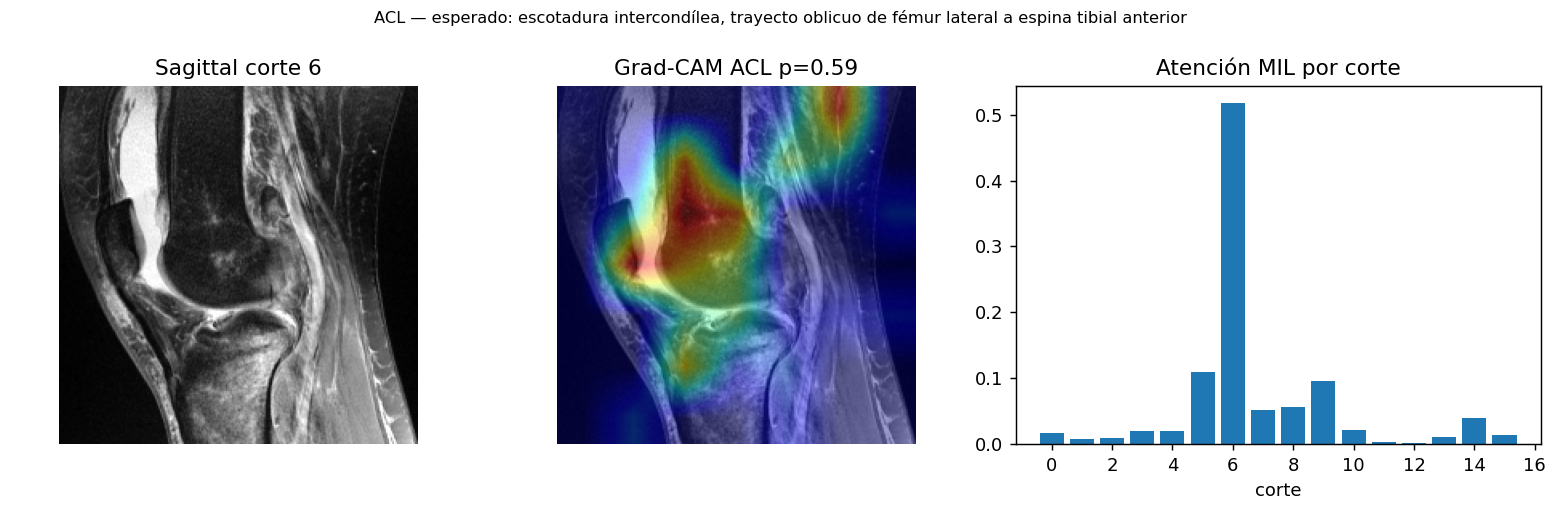

Effusion_02017580.png


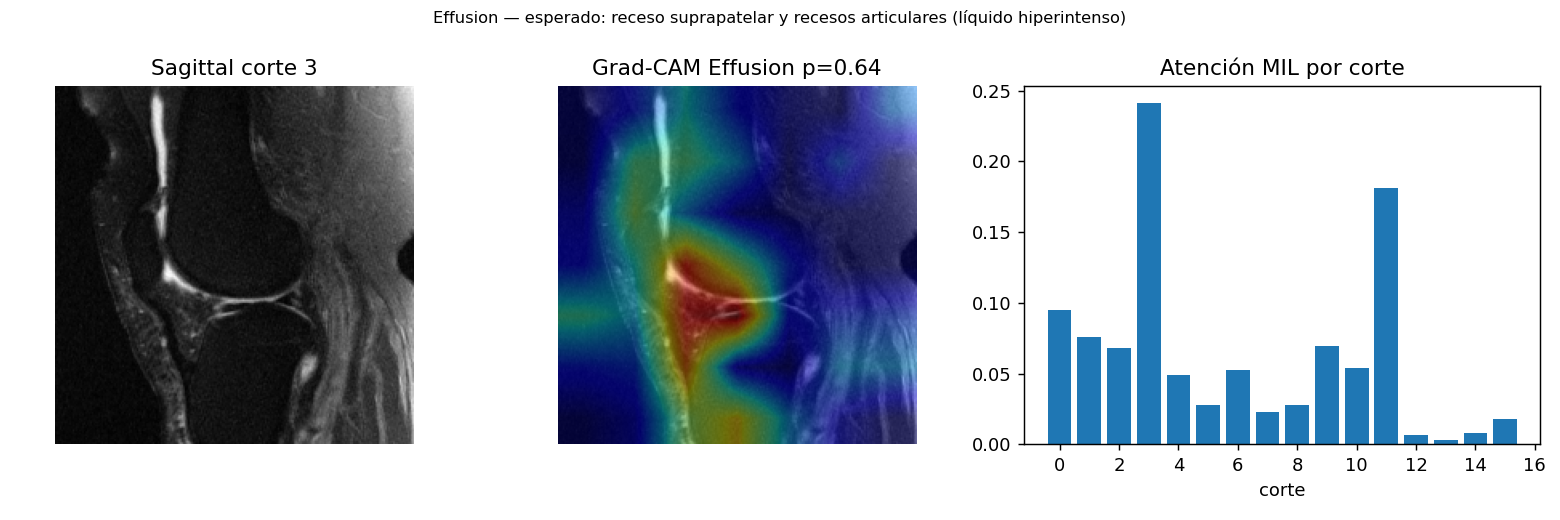

Effusion_13570435.png


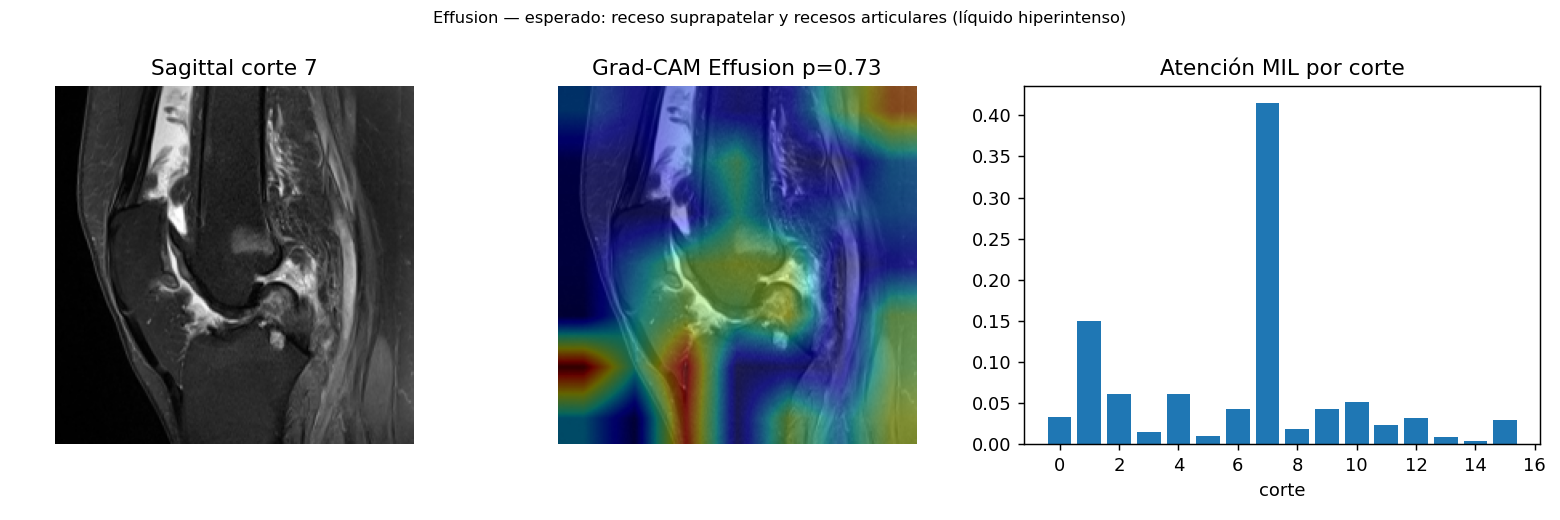

Effusion_63784327.png


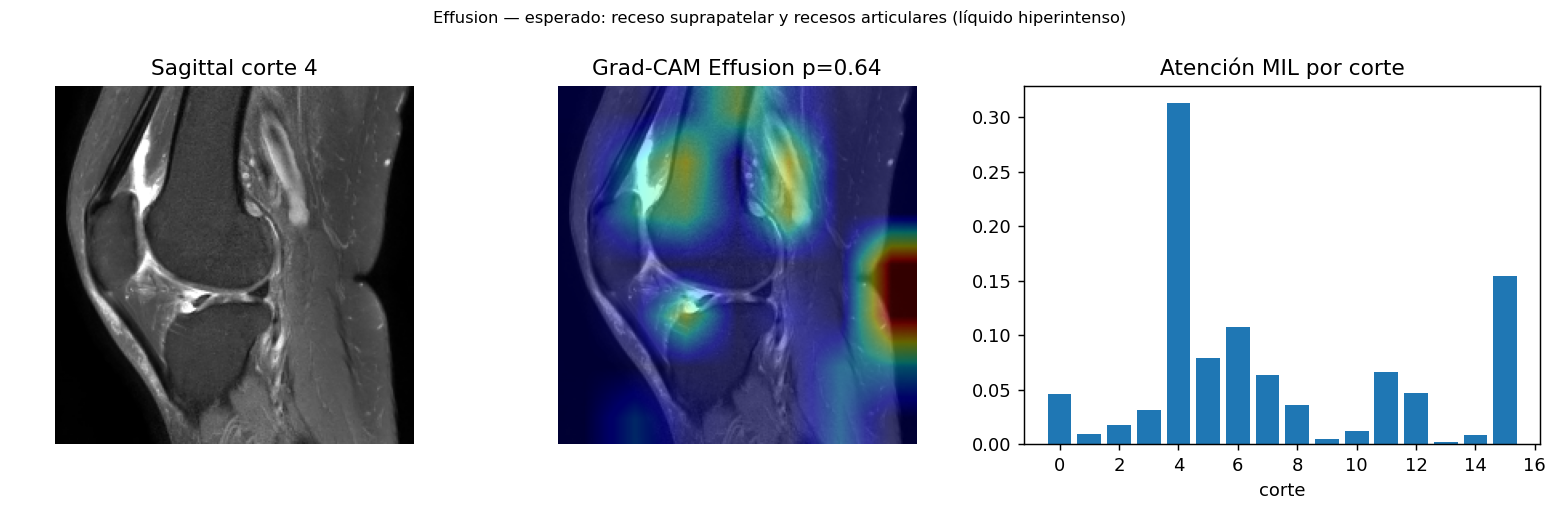

roc_gold.png


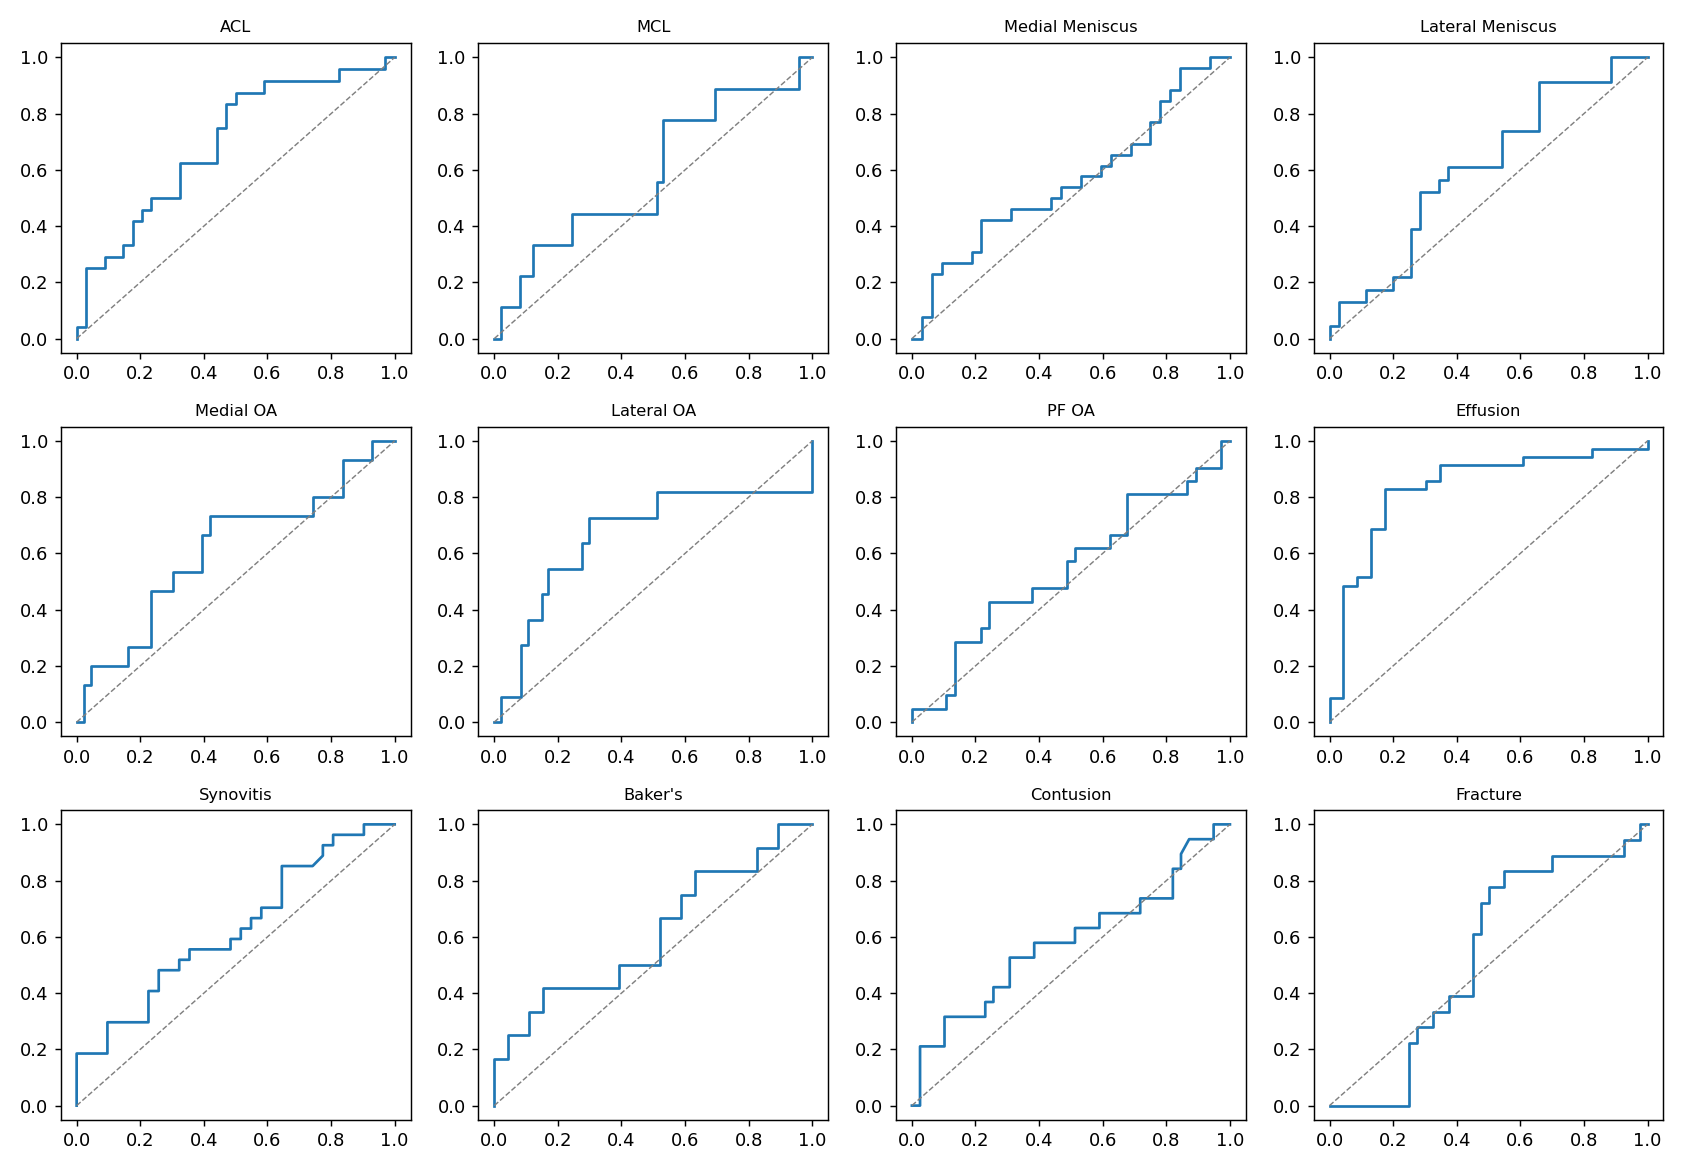

prevalence.png


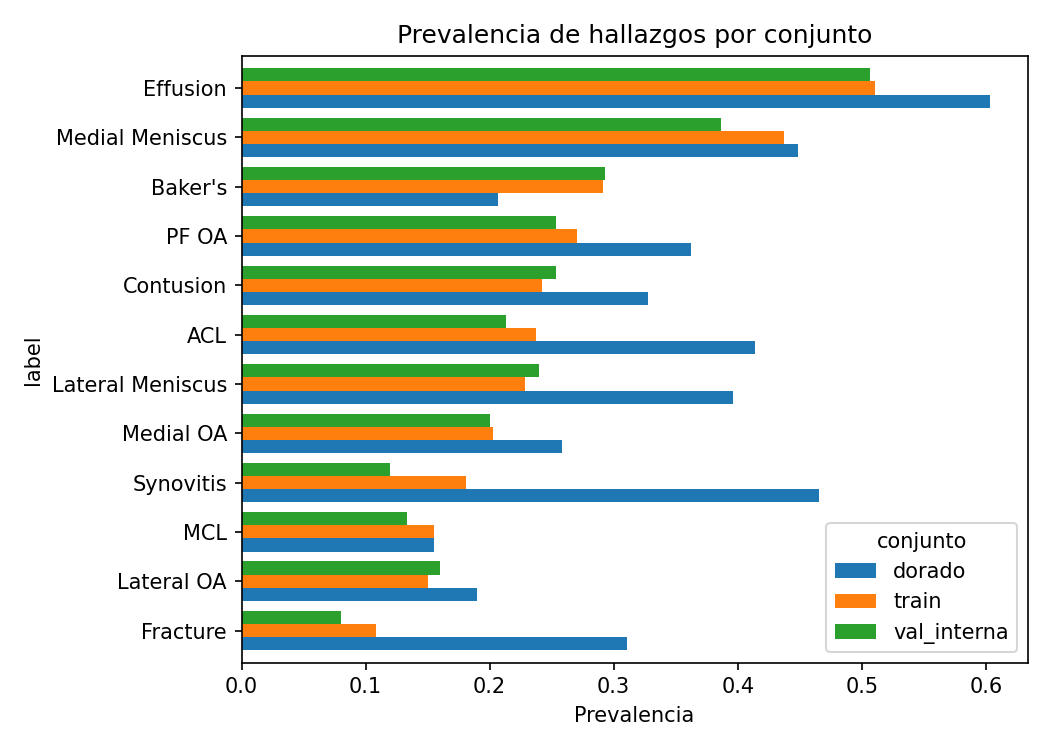

In [11]:
sh(f"python -m src.ablation --config {CFG} {OV} --aggregate", cwd=CODE)
sh(f"python -m src.compare --config {CFG} {OV}", cwd=CODE)
for f in ("comparacion_auc.png", "comparacion_por_hallazgo.png", "comparacion_curvas.png"):
    if os.path.exists(f"{WORK}/reports/{f}"):
        display(Image(f"{WORK}/reports/{f}"))
sh(f"python -m src.gradcam --config {CFG} {OV} --run base", cwd=CODE)
try:
    from IPython.display import Image, display
    for f in sorted(glob.glob(f"{WORK}/runs/base/gradcam/*.png"))[:6] + [f"{WORK}/runs/base/roc_gold.png", f"{WORK}/reports/prevalence.png"]:
        if os.path.exists(f):
            print(os.path.basename(f)); display(Image(f))
except ImportError:
    pass

## 8.1 · Resumen automático para la presentación
Reúne las cifras clave de cada entregable (generado desde los CSV, así que coincide con lo ejecutado).

In [12]:
sh(f"python -m src.report --config {CFG} {OV}", cwd=CODE)
from IPython.display import Markdown
display(Markdown(open(f"{WORK}/reports/resumen_presentacion.md").read()))

[reporte] → /kaggle/working/work/reports/resumen_presentacion.md


# Pregunta 1 — Resumen de resultados

Generado automáticamente por `src/report.py`.

## 1. Etiquetas débiles y su validación (entregable 1)

### Iteraciones del extractor (vs. dorados)

| version                    | parte   |   n |   acuerdo |   sensibilidad |   kappa_medio |   tasa_ruido |
|:---------------------------|:--------|----:|----------:|---------------:|--------------:|-------------:|
| v1 · reglas iniciales      | todos   |  58 |     0.759 |          0.617 |         0.436 |        0.241 |
| v1 · reglas iniciales      | dev     |  29 |     0.764 |          0.591 |         0.413 |        0.236 |
| v1 · reglas iniciales      | test    |  29 |     0.753 |          0.64  |         0.45  |        0.247 |
| v2 · reglas ampliadas      | todos   |  58 |     0.782 |          0.704 |         0.486 |        0.218 |
| v2 · reglas ampliadas      | dev     |  29 |     0.787 |          0.704 |         0.465 |        0.213 |
| v2 · reglas ampliadas      | test    |  29 |     0.776 |          0.704 |         0.495 |        0.224 |
| ensemble · v2 + embeddings | todos   |  58 |     0.782 |          0.704 |         0.486 |        0.218 |
| ensemble · v2 + embeddings | dev     |  29 |     0.787 |          0.704 |         0.465 |        0.213 |
| ensemble · v2 + embeddings | test    |  29 |     0.776 |          0.704 |         0.495 |        0.224 |

### Resumen por método

| method   |   agreement |   sensitivity |   specificity |    f1 |   kappa |   noise_rate |
|:---------|------------:|--------------:|--------------:|------:|--------:|-------------:|
| embed    |       0.678 |         0.712 |         0.637 | 0.58  |   0.307 |        0.322 |
| final    |       0.782 |         0.695 |         0.806 | 0.664 |   0.486 |        0.218 |
| rules    |       0.782 |         0.695 |         0.806 | 0.664 |   0.486 |        0.218 |

### Sensibilidad por idioma, entregable 7 (sesgo lingüístico)

| version                    | idioma   |   n |   acuerdo |   sensibilidad |   kappa_medio |   tasa_ruido |
|:---------------------------|:---------|----:|----------:|---------------:|--------------:|-------------:|
| v1 · reglas iniciales      | bg       |   3 |     0.667 |          0     |         0     |        0.333 |
| v1 · reglas iniciales      | de       |   2 |     0.667 |          0.6   |         0.222 |        0.333 |
| v1 · reglas iniciales      | el       |   3 |     0.472 |          0.053 |         0.036 |        0.528 |
| v1 · reglas iniciales      | en       |  28 |     0.812 |          0.843 |         0.57  |        0.188 |
| v1 · reglas iniciales      | es       |  10 |     0.817 |          0.759 |         0.405 |        0.183 |
| v1 · reglas iniciales      | hr       |   4 |     0.667 |          0.316 |         0.17  |        0.333 |
| v1 · reglas iniciales      | nl       |   2 |     0.667 |          0.467 |         0.3   |        0.333 |
| v1 · reglas iniciales      | tr       |   6 |     0.722 |          0.536 |         0.307 |        0.278 |
| v2 · reglas ampliadas      | bg       |   3 |     0.778 |          0.667 |         0.25  |        0.222 |
| v2 · reglas ampliadas      | de       |   2 |     0.708 |          0.6   |         0.25  |        0.292 |
| v2 · reglas ampliadas      | el       |   3 |     0.667 |          0.579 |         0.318 |        0.333 |
| v2 · reglas ampliadas      | en       |  28 |     0.815 |          0.824 |         0.57  |        0.185 |
| v2 · reglas ampliadas      | es       |  10 |     0.833 |          0.724 |         0.45  |        0.167 |
| v2 · reglas ampliadas      | hr       |   4 |     0.708 |          0.474 |         0.333 |        0.292 |
| v2 · reglas ampliadas      | nl       |   2 |     0.583 |          0.4   |         0.182 |        0.417 |
| v2 · reglas ampliadas      | tr       |   6 |     0.736 |          0.679 |         0.218 |        0.264 |
| ensemble · v2 + embeddings | bg       |   3 |     0.778 |          0.667 |         0.25  |        0.222 |
| ensemble · v2 + embeddings | de       |   2 |     0.708 |          0.6   |         0.25  |        0.292 |
| ensemble · v2 + embeddings | el       |   3 |     0.667 |          0.579 |         0.318 |        0.333 |
| ensemble · v2 + embeddings | en       |  28 |     0.815 |          0.824 |         0.57  |        0.185 |
| ensemble · v2 + embeddings | es       |  10 |     0.833 |          0.724 |         0.45  |        0.167 |
| ensemble · v2 + embeddings | hr       |   4 |     0.708 |          0.474 |         0.333 |        0.292 |
| ensemble · v2 + embeddings | nl       |   2 |     0.583 |          0.4   |         0.182 |        0.417 |
| ensemble · v2 + embeddings | tr       |   6 |     0.736 |          0.679 |         0.218 |        0.264 |

## 2. Desajuste de prevalencia débil vs. dorada (entregable 6)

Los dorados no son una muestra aleatoria del entrenamiento: la diferencia de prevalencia es un *dataset shift* que debe discutirse en el informe.

| hallazgo         |   prevalencia_debil |   prevalencia_dorada |   diferencia |
|:-----------------|--------------------:|---------------------:|-------------:|
| ACL              |               0.169 |                0.414 |        0.245 |
| MCL              |               0.099 |                0.155 |        0.057 |
| Medial Meniscus  |               0.416 |                0.448 |        0.032 |
| Lateral Meniscus |               0.209 |                0.397 |        0.187 |
| Medial OA        |               0.16  |                0.259 |        0.098 |
| Lateral OA       |               0.116 |                0.19  |        0.074 |
| PF OA            |               0.244 |                0.362 |        0.118 |
| Effusion         |               0.462 |                0.603 |        0.142 |
| Synovitis        |               0.108 |                0.466 |        0.357 |
| Baker's          |               0.231 |                0.207 |       -0.024 |
| Contusion        |               0.201 |                0.328 |        0.127 |
| Fracture         |               0.071 |                0.31  |        0.24  |

## 3. Modelos y ablaciones (entregables 2–4)

| experimento               | cambios                                                                 |   macro_auc_dorado |   ic95_inf |   ic95_sup |   macro_auc_val_interna |   macro_f1_dorado |
|:--------------------------|:------------------------------------------------------------------------|-------------------:|-----------:|-----------:|------------------------:|------------------:|
| loss_bce_noposw           | train.loss=bce, train.pos_weight=False, train.sampler=none              |             0.6462 |     0.586  |     0.7044 |                  0.7395 |            0.4062 |
| mil_mean                  | model.mil_pool=mean                                                     |             0.644  |     0.5849 |     0.6997 |                  0.7392 |            0.4229 |
| noisy_all                 | train.noisy_labels=all                                                  |             0.6385 |     0.5831 |     0.6929 |                  0.6995 |            0.4714 |
| gpool_avg                 | model.global_pool=avg                                                   |             0.6355 |     0.5825 |     0.6866 |                  0.7234 |            0.4445 |
| mil_max                   | model.mil_pool=max                                                      |             0.6293 |     0.5742 |     0.6778 |                  0.7335 |            0.4168 |
| plane_sag_cor             | train.planes=['Sagittal', 'Coronal']                                    |             0.6275 |     0.5653 |     0.6856 |                  0.7248 |            0.4375 |
| base                      | —                                                                       |             0.6221 |     0.5629 |     0.6805 |                  0.7172 |            0.4269 |
| loss_bce                  | train.loss=bce                                                          |             0.621  |     0.5646 |     0.6794 |                  0.6903 |            0.3929 |
| scratch_C1_k3_max_avg     | model.arch=scratch, model.global_pool=avg, model.scratch.pool=max       |             0.6207 |     0.5589 |     0.6796 |                  0.7074 |            0.4708 |
| resnet18                  | model.backbone=resnet18                                                 |             0.62   |     0.5591 |     0.68   |                  0.6855 |            0.4616 |
| scratch_C2_k5first        | model.arch=scratch, model.global_pool=avg, model.scratch.first_kernel=5 |             0.6096 |     0.5496 |     0.6685 |                  0.6746 |            0.4574 |
| scratch_C5_5blocks_avgmax | model.arch=scratch, model.global_pool=avgmax, model.scratch.blocks=5    |             0.6035 |     0.5461 |     0.656  |                  0.678  |            0.4013 |
| scratch_C4_stride_gmax    | model.arch=scratch, model.global_pool=max, model.scratch.pool=stride    |             0.5946 |     0.5244 |     0.654  |                  0.6832 |            0.4481 |
| noisy_highconf            | train.noisy_labels=high_conf_only                                       |             0.5902 |     0.5328 |     0.6473 |                  0.6036 |            0.4502 |
| scratch_C3_avgpool        | model.arch=scratch, model.global_pool=avg, model.scratch.pool=avg       |             0.5754 |     0.5228 |     0.626  |                  0.6631 |            0.4315 |
| plane_sag_only            | train.planes=['Sagittal']                                               |             0.5616 |     0.4993 |     0.6202 |                  0.7094 |            0.369  |
| effnet_b0                 | model.backbone=efficientnet_b0                                          |             0.5612 |     0.4849 |     0.6277 |                  0.6728 |            0.3952 |

### Δ macro-AUC vs. base (bootstrap pareado)

| experimento               |   delta_vs_base |   ic95_inf |   ic95_sup | significativo   |
|:--------------------------|----------------:|-----------:|-----------:|:----------------|
| loss_bce                  |         -0.0011 |    -0.0377 |     0.0367 | False           |
| noisy_highconf            |         -0.0319 |    -0.0912 |     0.0245 | False           |
| plane_sag_only            |         -0.0605 |    -0.1346 |     0.008  | False           |
| resnet18                  |         -0.0021 |    -0.0698 |     0.0648 | False           |
| scratch_C1_k3_max_avg     |         -0.0014 |    -0.0694 |     0.0678 | False           |
| noisy_all                 |          0.0164 |    -0.0318 |     0.0657 | False           |
| plane_sag_cor             |          0.0054 |    -0.0567 |     0.0627 | False           |
| mil_max                   |          0.0072 |    -0.0447 |     0.0665 | False           |
| mil_mean                  |          0.0219 |    -0.0366 |     0.0808 | False           |
| gpool_avg                 |          0.0134 |    -0.025  |     0.0564 | False           |
| effnet_b0                 |         -0.0609 |    -0.124  |    -0.0039 | True            |
| loss_bce_noposw           |          0.0241 |    -0.0297 |     0.0815 | False           |
| scratch_C2_k5first        |         -0.0125 |    -0.0784 |     0.0511 | False           |
| scratch_C3_avgpool        |         -0.0467 |    -0.1157 |     0.0167 | False           |
| scratch_C4_stride_gmax    |         -0.0275 |    -0.093  |     0.0398 | False           |
| scratch_C5_5blocks_avgmax |         -0.0186 |    -0.0781 |     0.05   | False           |

### AUC por hallazgo

| label            |   base |   loss_bce |   noisy_highconf |   plane_sag_only |   resnet18 |   scratch_C1_k3_max_avg |   noisy_all |   plane_sag_cor |   mil_max |   mil_mean |   gpool_avg |   effnet_b0 |   loss_bce_noposw |   scratch_C2_k5first |   scratch_C3_avgpool |   scratch_C4_stride_gmax |   scratch_C5_5blocks_avgmax |
|:-----------------|-------:|-----------:|-----------------:|-----------------:|-----------:|------------------------:|------------:|----------------:|----------:|-----------:|------------:|------------:|------------------:|---------------------:|---------------------:|-------------------------:|----------------------------:|
| ACL              |  0.696 |      0.571 |            0.661 |            0.491 |      0.553 |                   0.613 |       0.655 |           0.587 |     0.641 |      0.653 |       0.626 |       0.648 |             0.618 |                0.588 |                0.583 |                    0.66  |                       0.504 |
| MCL              |  0.59  |      0.621 |            0.576 |            0.554 |      0.712 |                   0.755 |       0.737 |           0.553 |     0.651 |      0.624 |       0.646 |       0.601 |             0.556 |                0.721 |                0.565 |                    0.558 |                       0.583 |
| Medial Meniscus  |  0.561 |      0.606 |            0.543 |            0.44  |      0.483 |                   0.602 |       0.589 |           0.362 |     0.556 |      0.429 |       0.592 |       0.471 |             0.566 |                0.538 |                0.436 |                    0.544 |                       0.498 |
| Lateral Meniscus |  0.609 |      0.684 |            0.5   |            0.482 |      0.737 |                   0.706 |       0.534 |           0.639 |     0.594 |      0.708 |       0.64  |       0.542 |             0.617 |                0.722 |                0.647 |                    0.648 |                       0.627 |
| Medial OA        |  0.612 |      0.606 |            0.69  |            0.65  |      0.575 |                   0.487 |       0.575 |           0.636 |     0.605 |      0.552 |       0.647 |       0.527 |             0.581 |                0.496 |                0.35  |                    0.58  |                       0.509 |
| Lateral OA       |  0.663 |      0.659 |            0.555 |            0.665 |      0.558 |                   0.718 |       0.627 |           0.75  |     0.495 |      0.685 |       0.658 |       0.675 |             0.615 |                0.619 |                0.731 |                    0.631 |                       0.71  |
| PF OA            |  0.544 |      0.521 |            0.533 |            0.52  |      0.548 |                   0.453 |       0.671 |           0.583 |     0.524 |      0.559 |       0.586 |       0.61  |             0.52  |                0.569 |                0.505 |                    0.606 |                       0.676 |
| Effusion         |  0.835 |      0.805 |            0.697 |            0.769 |      0.666 |                   0.868 |       0.744 |           0.842 |     0.881 |      0.922 |       0.845 |       0.753 |             0.85  |                0.87  |                0.839 |                    0.748 |                       0.824 |
| Synovitis        |  0.625 |      0.588 |            0.576 |            0.622 |      0.661 |                   0.651 |       0.566 |           0.661 |     0.55  |      0.593 |       0.618 |       0.618 |             0.639 |                0.648 |                0.57  |                    0.576 |                       0.652 |
| Baker's          |  0.611 |      0.63  |            0.614 |            0.583 |      0.645 |                   0.571 |       0.792 |           0.69  |     0.678 |      0.65  |       0.605 |       0.475 |             0.788 |                0.611 |                0.554 |                    0.582 |                       0.659 |
| Contusion        |  0.584 |      0.563 |            0.551 |            0.516 |      0.619 |                   0.464 |       0.57  |           0.599 |     0.704 |      0.653 |       0.563 |       0.34  |             0.7   |                0.49  |                0.594 |                    0.538 |                       0.517 |
| Fracture         |  0.535 |      0.597 |            0.588 |            0.445 |      0.682 |                   0.56  |       0.603 |           0.628 |     0.674 |      0.701 |       0.603 |       0.475 |             0.704 |                0.444 |                0.532 |                    0.464 |                       0.483 |

## 4. Figuras para el informe

- `reports/extractor_iteraciones.png`

- `reports/comparacion_auc.png`

- `reports/comparacion_por_hallazgo.png`

- `reports/comparacion_curvas.png`

- `reports/prevalence.png`


## 5. Grad-CAM (entregable 5)

Ver `runs/<experimento>/gradcam/` (paneles por hallazgo con región anatómica esperada).


## 9 · Empaquetar resultados
Genera `resultados_<modo>.zip` (métricas, tablas, figuras, historiales; sin los pesos `.pt` pesados) para el informe.
Descárgalo desde el panel *Output* (o hazme llegar el contenido de `validation_report.md` y `ablations.md`).

In [13]:
zpath = f"{WORK_ROOT}/resultados_{MODO}.zip"
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(WORK):
        for f in files:
            if f.endswith((".pt", ".npy")):
                continue
            full = os.path.join(root, f)
            z.write(full, os.path.relpath(full, WORK))
print(zpath, f"{os.path.getsize(zpath) / 1e6:.1f} MB")

/kaggle/working/resultados_completo.zip 8.0 MB


## ¿Y ahora?
- **Si MODO="prueba" terminó sin errores** → pégame la salida de las secciones 4, 5 y 7 (diagnóstico, validación y tabla). Ajusto el extractor a los reportes reales y pasas a `MODO = "completo"`.
- **Modo completo**: primero `GRUPO = "A"` (6 experimentos esenciales). Al terminar: *Save Version*; después una segunda versión con `GRUPO = "B"` y `RESUMIR_DESDE` apuntando a la salida de la primera.


In [3]:
import shutil
from IPython.display import FileLink

# 1. Comprime todo el output en un solo archivo
shutil.make_archive('salida_laptop', 'zip', '/kaggle/working')

# 2. Crea un enlace de descarga inmediata
FileLink(r'salida_laptop.zip')


/kaggle/working/salida_laptop.zip